In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [4]:
# Load dataset
df = pd.read_excel(r"C:\Users\Sujal\OneDrive\Internship\OLA-Ride-Insights\data\OLA_DataSet.xlsx", sheet_name="July")

# Display first 5 records
df.head()

,Date,Time,Booking_ID,Booking_Status,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,V_TAT,C_TAT,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver,Incomplete_Rides,Incomplete_Rides_Reason,Booking_Value,Payment_Method,Ride_Distance,Driver_Ratings,Customer_Rating,Vehicle Images
0,2024-07-26 14:00:00,14:00:00,CNR7153255142,Canceled by Driver,CID713523,Prime Sedan,Tumkur Road,RT Nagar,NaN,NaN,NaN,Personal & Car related issue,NaN,NaN,444,NaN,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/14183/1...
1,2024-07-25 22:20:00,22:20:00,CNR2940424040,Success,CID225428,Bike,Magadi Road,Varthur,203.0,30.0,NaN,NaN,No,NaN,158,Cash,13,4.1,4.0,https://cdn-icons-png.flaticon.com/128/9983/99...
2,2024-07-30 19:59:00,19:59:00,CNR2982357879,Success,CID270156,Prime SUV,Sahakar Nagar,Varthur,238.0,130.0,NaN,NaN,No,NaN,386,UPI,40,4.2,4.8,https://cdn-icons-png.flaticon.com/128/9983/99...
3,2024-07-22 03:15:00,03:15:00,CNR2395710036,Canceled by Customer,CID581320,eBike,HSR Layout,Vijayanagar,NaN,NaN,Driver is not moving towards pickup location,NaN,NaN,NaN,384,NaN,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/6839/68...
4,2024-07-02 09:02:00,09:02:00,CNR1797421769,Success,CID939555,Mini,Rajajinagar,Chamarajpet,252.0,80.0,NaN,NaN,No,NaN,822,Credit Card,45,4.0,3.0,https://cdn-icons-png.flaticon.com/128/3202/32...


In [6]:
df.shape

(103024, 20)

In [9]:
df.columns.tolist()

['Date',
 'Time',
 'Booking_ID',
 'Booking_Status',
 'Customer_ID',
 'Vehicle_Type',
 'Pickup_Location',
 'Drop_Location',
 'V_TAT',
 'C_TAT',
 'Canceled_Rides_by_Customer',
 'Canceled_Rides_by_Driver',
 'Incomplete_Rides',
 'Incomplete_Rides_Reason',
 'Booking_Value',
 'Payment_Method',
 'Ride_Distance',
 'Driver_Ratings',
 'Customer_Rating',
 'Vehicle Images']

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103024 entries, 0 to 103023
Data columns (total 20 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   Date                        103024 non-null  datetime64[ns]
 1   Time                        103024 non-null  object        
 2   Booking_ID                  103024 non-null  object        
 3   Booking_Status              103024 non-null  object        
 4   Customer_ID                 103024 non-null  object        
 5   Vehicle_Type                103024 non-null  object        
 6   Pickup_Location             103024 non-null  object        
 7   Drop_Location               103024 non-null  object        
 8   V_TAT                       63967 non-null   float64       
 9   C_TAT                       63967 non-null   float64       
 10  Canceled_Rides_by_Customer  10499 non-null   object        
 11  Canceled_Rides_by_Driver    18434 non-n

In [11]:
df.describe(include="all").T


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Date,103024,NaN,NaN,NaN,2024-07-16 11:31:38.879678720,2024-07-01 00:00:00,2024-07-08 18:41:00,2024-07-16 11:23:00,2024-07-24 05:18:00,2024-07-31 23:58:00,NaN
Time,103024,1440,00:53:00,101,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Booking_ID,103024,103024,CNR3204013257,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Booking_Status,103024,4,Success,63967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,103024,94544,CID954071,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vehicle_Type,103024,7,Prime Sedan,14877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pickup_Location,103024,50,Banashankari,2201,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Drop_Location,103024,50,Peenya,2159,NaN,NaN,NaN,NaN,NaN,NaN,NaN
V_TAT,63967.0,NaN,NaN,NaN,170.876952,35.0,98.0,168.0,238.0,308.0,80.80364
C_TAT,63967.0,NaN,NaN,NaN,84.873372,25.0,55.0,85.0,115.0,145.0,36.0051


In [12]:
print(df.isnull().sum())

Date                              0
Time                              0
Booking_ID                        0
Booking_Status                    0
Customer_ID                       0
Vehicle_Type                      0
Pickup_Location                   0
Drop_Location                     0
V_TAT                         39057
C_TAT                         39057
Canceled_Rides_by_Customer    92525
Canceled_Rides_by_Driver      84590
Incomplete_Rides              39057
Incomplete_Rides_Reason       99098
Booking_Value                     0
Payment_Method                39057
Ride_Distance                     0
Driver_Ratings                39057
Customer_Rating               39057
Vehicle Images                    0
dtype: int64


In [13]:
null_counts = (
    df.astype("string")
      .apply(lambda col: col.str.strip().str.lower().eq("null").sum())
)

print("\nText-based null values:")
print(null_counts[null_counts > 0])


Text-based null values:
Series([], dtype: int64)


In [14]:
print("Total duplicate rows:", df.duplicated().sum())

# Check duplicate Booking IDs
print("Duplicate Booking IDs:",
      df["Booking_ID"].duplicated().sum())

Total duplicate rows: 0
Duplicate Booking IDs: 0


In [15]:
clean_df = df.copy()

# Convert text-based null values into actual NaN
clean_df = clean_df.replace(
    r'(?i)^\s*null\s*$',
    np.nan,
    regex=True
)

# Remove duplicate records
clean_df = clean_df.drop_duplicates()

# Standardize vehicle names
clean_df["Vehicle_Type"] = (
    clean_df["Vehicle_Type"]
    .astype("string")
    .str.strip()
    .replace({"eBike": "E-Bike"})
)

# Convert date and time
clean_df["Date"] = pd.to_datetime(
    clean_df["Date"], errors="coerce"
)

clean_df["Time"] = pd.to_datetime(
    clean_df["Time"].astype(str),
    format="%H:%M:%S",
    errors="coerce"
).dt.time

# Check results
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103024 entries, 0 to 103023
Data columns (total 20 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   Date                        103024 non-null  datetime64[ns]
 1   Time                        103024 non-null  object        
 2   Booking_ID                  103024 non-null  object        
 3   Booking_Status              103024 non-null  object        
 4   Customer_ID                 103024 non-null  object        
 5   Vehicle_Type                103024 non-null  string        
 6   Pickup_Location             103024 non-null  object        
 7   Drop_Location               103024 non-null  object        
 8   V_TAT                       63967 non-null   float64       
 9   C_TAT                       63967 non-null   float64       
 10  Canceled_Rides_by_Customer  10499 non-null   object        
 11  Canceled_Rides_by_Driver    18434 non-n

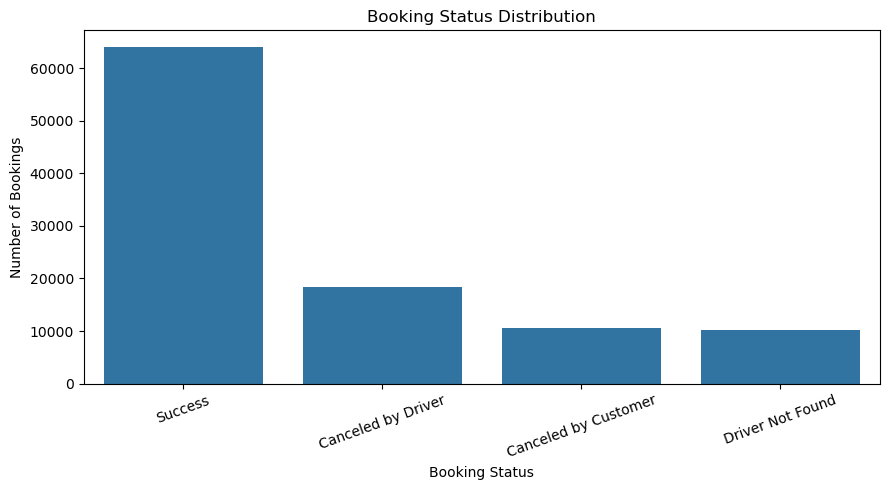

In [16]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=clean_df,
    x="Booking_Status",
    order=clean_df["Booking_Status"].value_counts().index
)

plt.title("Booking Status Distribution")
plt.xlabel("Booking Status")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

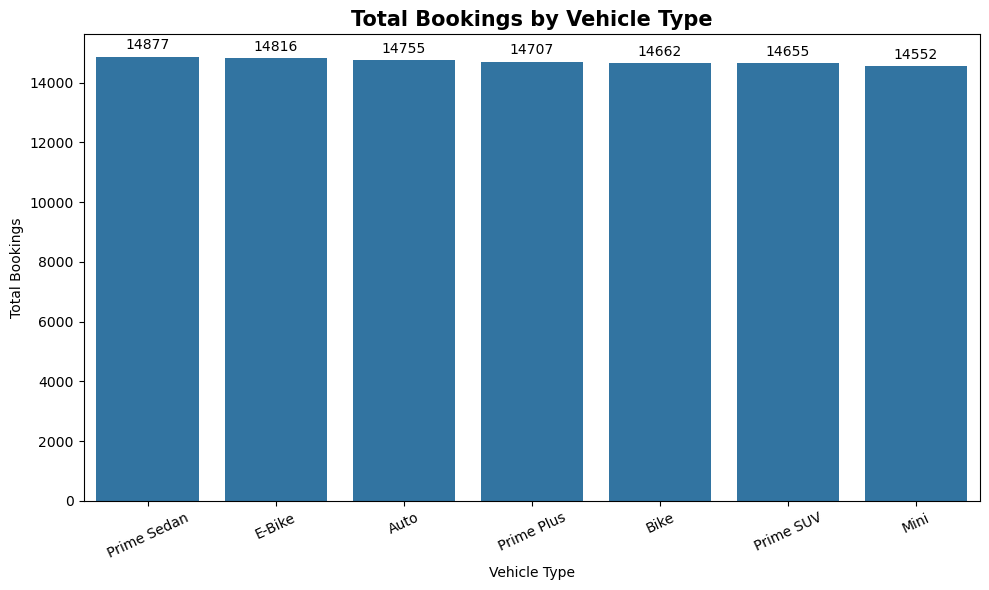

In [22]:
plt.figure(figsize=(10, 6))

vehicle_count = (
    clean_df["Vehicle_Type"]
    .value_counts()
    .sort_values(ascending=False)
)

ax = sns.barplot(
    x=vehicle_count.index,
    y=vehicle_count.values
)

ax.bar_label(ax.containers[0], padding=3)

plt.title("Total Bookings by Vehicle Type",
          fontsize=15, fontweight="bold")
plt.xlabel("Vehicle Type")
plt.ylabel("Total Bookings")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

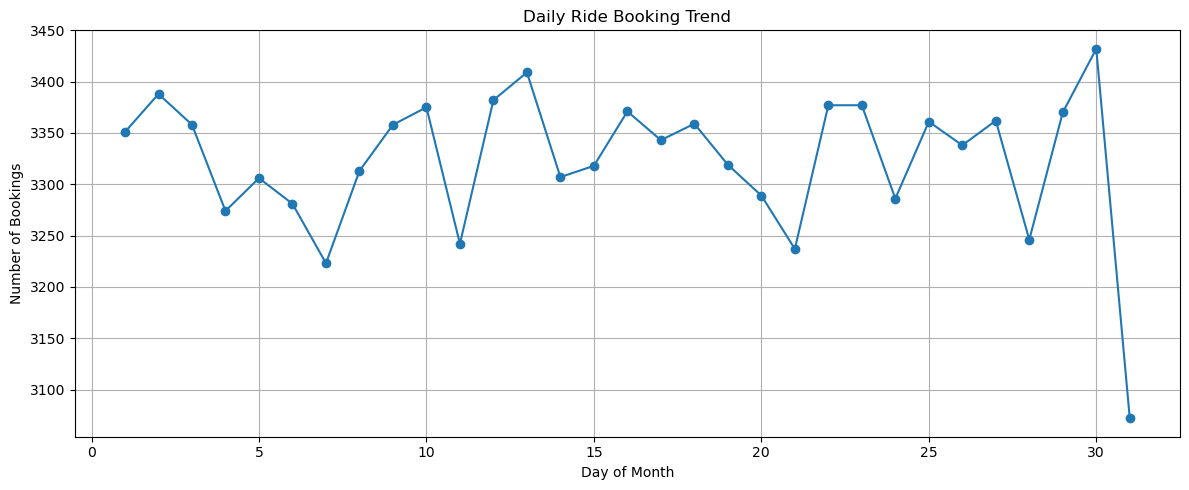

In [19]:
daily_bookings = (
    clean_df.groupby(clean_df["Date"].dt.day)
    ["Booking_ID"].count()
)

plt.figure(figsize=(12, 5))

daily_bookings.plot(kind="line", marker="o")

plt.title("Daily Ride Booking Trend")
plt.xlabel("Day of Month")
plt.ylabel("Number of Bookings")
plt.grid(True)
plt.tight_layout()
plt.show()

Payment_Method
Cash           35022
UPI            25881
Credit Card     2435
Debit Card       629
Name: count, dtype: int64


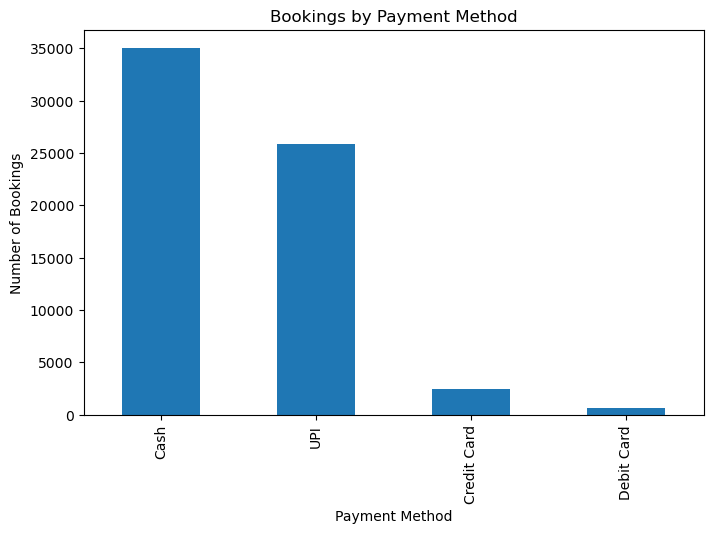

In [20]:
payment_count = clean_df["Payment_Method"].value_counts()

print(payment_count)

payment_count.plot(
    kind="bar",
    figsize=(8,5),
    title="Bookings by Payment Method"
)

plt.xlabel("Payment Method")
plt.ylabel("Number of Bookings")
plt.show()

In [24]:
successful_rides = clean_df[
    clean_df["Booking_Status"] == "Success"
]

total_revenue = successful_rides["Booking_Value"].sum()

print("Total Revenue:", total_revenue)
print("Average Booking Value:",
      successful_rides["Booking_Value"].mean())


Total Revenue: 35080467
Average Booking Value: 548.4150733972205


In [25]:
revenue_vehicle = (
    successful_rides.groupby("Vehicle_Type")["Booking_Value"]
    .sum()
    .sort_values(ascending=False)
)

print(revenue_vehicle)

Vehicle_Type
Prime Sedan    5224050
E-Bike         5054662
Auto           5051846
Prime Plus     5015165
Bike           4971968
Mini           4885961
Prime SUV      4876815
Name: Booking_Value, dtype: int64


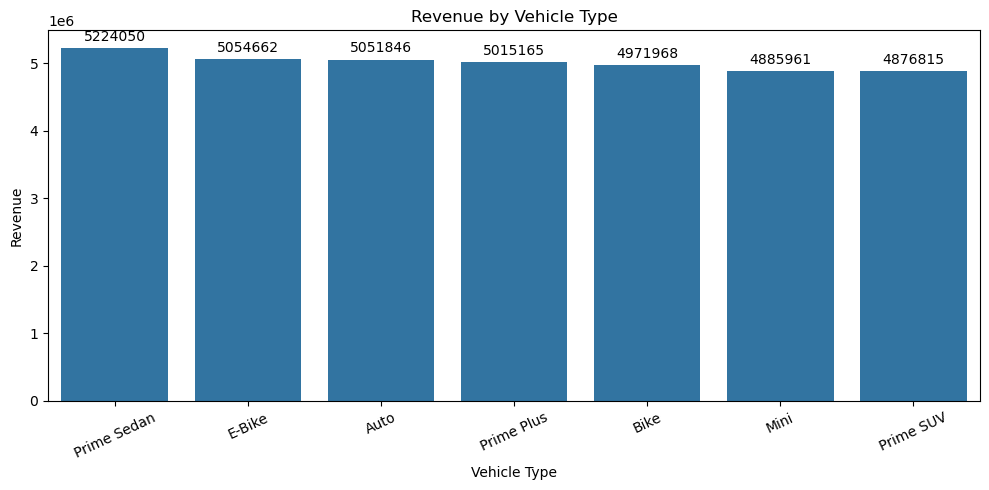

In [26]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=revenue_vehicle.index,
    y=revenue_vehicle.values
)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

plt.title("Revenue by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Revenue")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [27]:
print("Average Customer Rating:",
      clean_df["Customer_Rating"].mean())

print("Average Driver Rating:",
      clean_df["Driver_Ratings"].mean())

Average Customer Rating: 3.9983131927400057
Average Driver Rating: 3.9974565010083327


In [28]:
rating_analysis = clean_df.groupby("Vehicle_Type")[
    ["Customer_Rating", "Driver_Ratings"]
].mean()

print(rating_analysis)

              Customer_Rating  Driver_Ratings
Vehicle_Type                                 
Auto                 3.998811        4.003938
Bike                 3.993376        3.984651
E-Bike               3.987854        4.006743
Mini                 3.997731        3.992807
Prime Plus           4.009499        3.997785
Prime SUV            3.999378        4.005780
Prime Sedan          4.001589        3.990681


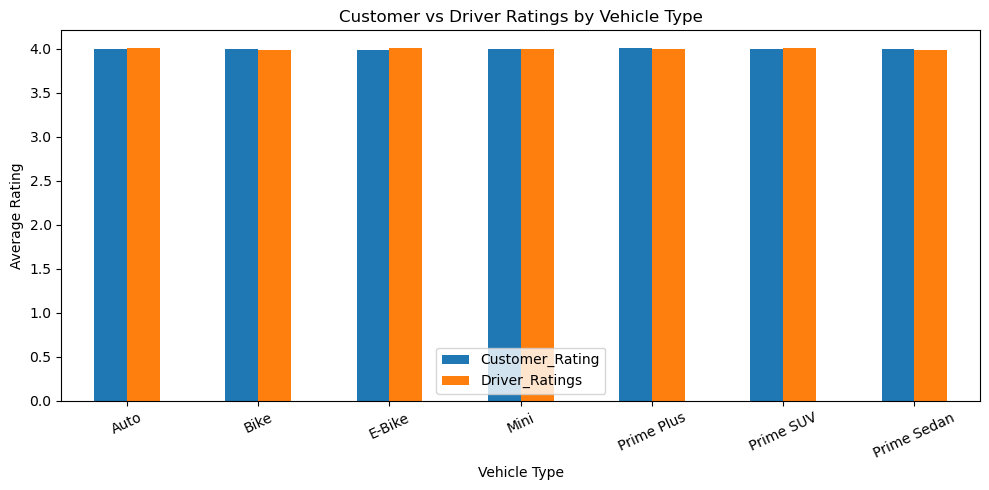

In [29]:
rating_analysis.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Customer vs Driver Ratings by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Rating")
plt.xticks(rotation=25)
plt.legend()
plt.tight_layout()
plt.show()

In [30]:
print(clean_df["Ride_Distance"].describe())

count    103024.000000
mean         14.189927
std          15.776270
min           0.000000
25%           0.000000
50%           8.000000
75%          26.000000
max          49.000000
Name: Ride_Distance, dtype: float64


In [31]:
distance_analysis = (
    clean_df.groupby("Vehicle_Type")["Ride_Distance"]
    .mean()
    .sort_values(ascending=False)
)

print(distance_analysis)

Vehicle_Type
Prime Sedan    15.764939
E-Bike         15.580589
Bike           15.533079
Mini           15.510102
Prime Plus     15.447474
Prime SUV      15.274514
Auto            6.238089
Name: Ride_Distance, dtype: float64


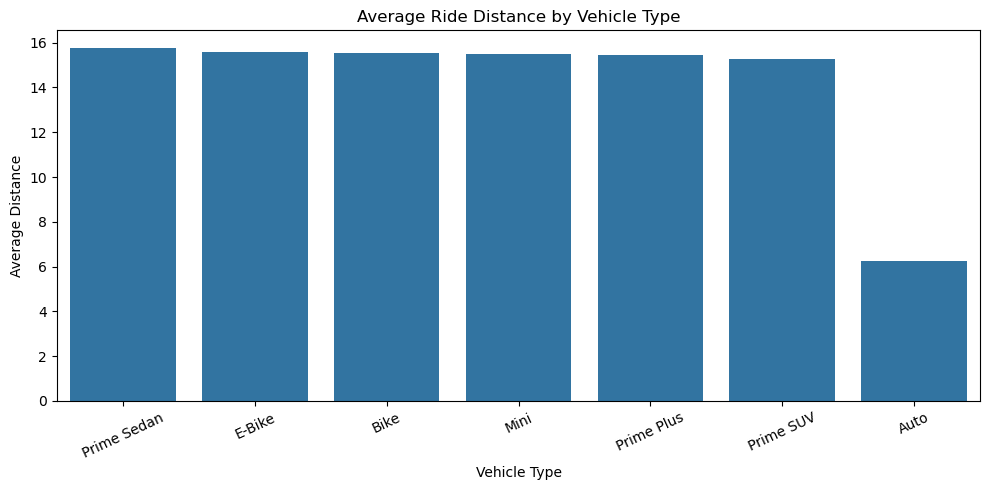

In [32]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=distance_analysis.index,
    y=distance_analysis.values
)

plt.title("Average Ride Distance by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Distance")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [33]:
clean_df.to_csv(
    "../data/cleaned_ola_data.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!
